# Shoaling: several simulated fish in one dish

The data never show a fish another fish. Here each simulated fish sees the others as **moving dots**: do fish that
were trained only on dots shoal? This notebook shows how the simulation is built, runs a small group, and plays one
video per condition of the thesis (Results, "Multiple fish"; the tables are in `notebooks/09_shoaling`).

The videos are cut from the shoal runs when they exist (`output/multi_fish/`, not in the output zip); without them
each video simulates only the groups it shows, the same groups as in the full runs, so the same video (about half a
minute per group and 1-2 min of rendering per video). Videos are written once to `output/experiments/shoaling/`.

<a id="contents"></a>
**Contents**

1. [How the simulation is built](#built)
2. [A small example](#example)
3. [A video of your own](#own-video)
4. [The thesis videos](#thesis)

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Video, display

from twin import multi_fish as MF
from twin import shoal_videos as SV
from twin import videos as V

def show(mp4, width=900):
    """Play a video in the notebook (a link to the file, not embedded: open the notebook locally to play it)."""
    try:
        p = Path(os.path.relpath(mp4)).as_posix()
    except ValueError:                                   # another drive
        p = str(mp4)
    display(Video(p, embed=False, width=width, html_attributes="controls loop muted"))

<a id="built"></a>
## How the simulation is built

`twin/multi_fish.py`. Every fish runs the trained generator unchanged; only its stimulus provider is new:

- **coupling**: one thread per fish; the fish with the earliest pending bout goes next, and at its bout onset it
  reads where the others are, so every fish sees each other fish after that fish's earlier bouts (deterministic);
- **perception**: the others within 78 mm, at any bearing, always as *moving* dots; neighbours close together are
  pooled into one dot group (the spread a trained group of that size had), at most 8 dots per group;
- **rule**: the groups are combined by the *effects* rule, the one that reproduces averaging-then-choosing
  (`experiments/two_dot_groups.ipynb`);
- **clock**: the block clock is held at 60 s, so a neighbour never looks like a block onset;
- **dishes**: the training dish (30 min, read from 5 min) and one of five times its radius (60 min, read from
  10 min, the fish starting within 25 mm of each other); every wall mechanism scales with the radius;
- **variants**: the group repulsion term (`twin/grouprep_fit.py`, calibrated on the screen, x1 to x8) and a collision
  rule that forbids overlap; **blind** fish (the same fish, nobody shown) are the reference.

[↑ back to contents](#contents)

<a id="example"></a>
## A small example

Five F fish (seed 0) in the training dish for 5 minutes, seeing each other and blind (about 10 s). The nearest
neighbour distance of the fish that see each other drops below that of the same fish blind: they shoal.

[↑ back to contents](#contents)

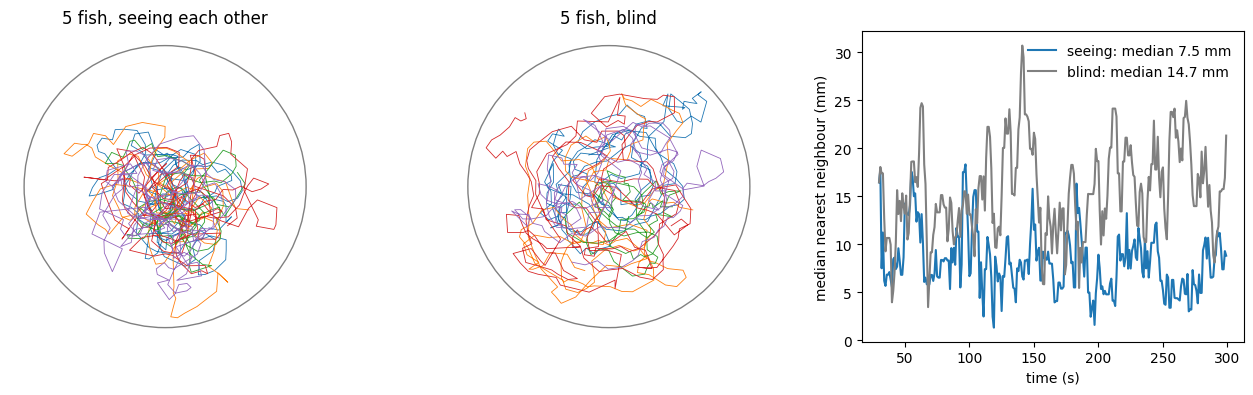

In [2]:
spec = MF._cond("14f", 5, 1, 1, 300)                         # model, fish, groups, dish (x radius), seconds
seeing = MF.run_group(spec, 0)
blind = MF.run_group(dict(spec, blind=True), 0)

taus = np.arange(30.0, 300.0, 1.0)
fig, (a0, a1, a2) = plt.subplots(1, 3, figsize=(13, 4))
cx, cy, R = MF.dish(1)
for ax, grp, lab in ((a0, seeing, "seeing each other"), (a1, blind, "blind")):
    ax.add_patch(plt.Circle((cx, cy), R, fill=False, color="0.5"))
    for f in grp:
        ax.plot(f["x"], f["y"], lw=0.6)
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.axis("off"); ax.set_title(f"5 fish, {lab}")
for grp, lab, col in ((seeing, "seeing", "C0"), (blind, "blind", "0.5")):
    P = np.array([MF.pos_at(f, taus) for f in grp]) / MF.PX_MM
    D = np.linalg.norm(P[:, None] - P[None], axis=-1); D[np.arange(5), np.arange(5)] = np.inf
    a2.plot(taus, np.median(D.min(1), 0), color=col, label=f"{lab}: median {np.median(D.min(1)):.1f} mm")
a2.set(xlabel="time (s)", ylabel="median nearest neighbour (mm)"); a2.legend(frameon=False)
plt.tight_layout(); plt.show()

<a id="own-video"></a>
## A video of your own

Every video of the repository is drawn by `twin/videos.py`: a list of panels (fish positions in mm, the view, the
dish) played over frame times. A bout becomes a 0.2 s straight glide; between bouts the fish holds still. Here the
first 2 minutes of the example, at 4x speed (about 40 s to render).

[↑ back to contents](#contents)

In [3]:
taus = np.arange(0.0, 120.0, 4.0 / V.FPS)
panels = []
for grp, lab in ((seeing, "5 F fish, seeing each other"), (blind, "the same fish, blind")):
    P = np.array([V.frames(f["t"], f["x"], f["y"], taus) for f in grp])
    xy = np.stack([(P[..., 0] - cx) / MF.PX_MM, (P[..., 1] - cy) / MF.PX_MM], -1)
    r = R / MF.PX_MM * 1.03
    panels.append(dict(xy=xy, view=(-r, r, -r, r), dish=(0.0, 0.0, R / MF.PX_MM), label=lab))
mp4 = V.write(panels, taus, "A small example", V.clock_footer(taus, 4), SV.LITE / "example.mp4", speed=4)
show(mp4, width=700)

<a id="thesis"></a>
## The thesis videos

Seed 0. The window is not chosen to look good: a random group and a random 3 minutes of the readout period, from a
fixed seed (`twin/shoal_videos.py`); each panel's title gives that window's median nearest-neighbour distance (and,
with the full runs, the condition's median over all groups). Each video comes with what to look for and where the
model fails.

[↑ back to contents](#contents)

### F, groups of 5, training dish

**What to watch.** They come together (dispersion D -0.30, nearest neighbour 8.5 mm against 15 mm blind), but the fish swim on top of each other: neighbours are as dense at contact as a few millimetres away, so no distance is held, and the headings stay random (alignment 0.42 against 0.40 blind).

In [4]:
show(SV.video("F_A1_N5"))

### F, groups of 5, 5x dish

**What to watch.** Started together, without a wall to hold them, they stay together for the whole hour (D -0.68 | -0.60): the attraction is real. Watch the clump: fish pass through each other and never swim in a common direction.

In [5]:
show(SV.video("F_A5_N5"))

### Repulsion and collision, groups of 5, training dish

**What to watch.** The repulsion term at the calibrated strength (x1) opens only a slight gap; the real gap needs about x4, where the fish lose part of their attraction. The collision rule forbids overlap but leaves 2-4 mm as crowded: a floor, not a distance. None of them aligns the fish: they still chase their neighbours' positions.

In [6]:
show(SV.video("rep_A1_N5"))

### Repulsion and collision, groups of 5, 5x dish

**What to watch.** The same in the large dish: the shoal holds together under every variant, contacts disappear with the collision rule, and still no common heading.

In [7]:
show(SV.video("rep_A5_N5"))

### Pairs: F, D4 trained on the screen, D4 + dot direction, training dish

**What to watch.** F's pair stays close but overlaps; the screen-trained D4 keeps a gap at contact but attracts less; with the dot's direction of motion the pair aligns slightly (0.02-0.04 above pseudo-pairs). Watch for two fish swimming side by side: no model does it.

In [8]:
show(SV.video("pairs_A1"))

### Pairs, 5x dish

**What to watch.** In the large dish the screen-trained pairs drift apart (median distance 60-66 mm, against 25-27 mm for F): they gain spacing and a little alignment and lose the cohesion.

In [9]:
show(SV.video("pairs_A5"))